# Lab: Macro-level structure and synthetic models

<a href="../downloads/lab_04.ipynb"
   class="btn btn-outline-primary"
   download>
  Download notebook (.ipynb)
</a>

This lab combines the two parts of this week's content: measures of macro-level structures and synthetic network models. The objective is to compute the measures on one of the networks that you produced during the previous labs (e.g. a retweet network) and also on the corresponding synthetic networks produced using different models based on different network generation mechanisms. The expected final result of this lab is a table with the different networks as rows and the different measures as columns, allowing you to reflect about the models that best describe your empirical network and possible mechanisms behind it.

The lab consists of three parts. In the first part you generate networks - the objective is to become familiar with the different synthetic models and their parameters. The second part has two objectives: compute the measures discussed in the theory, and _most importantly_ for each measure compare how it varies across the different networks, reflecting on what you learn from these comparisons. The third part is just the compilation of all your previous results into a summary table, that you can use both to consolidate the different observations and reflections made during the lab and _most importantly (?)_ as a basis for the presentation to the teachers on Friday.

## Contents

- [PART 1: Network generation](#PART-1:-Network-generation)
- [PART 2: Measures](#PART-2:-Measures)
- [PART 3: Summary](#PART-3:-Summary)

## PART 1: Network generation

### Setup: load (or build) the empirical network

Run this cell first. It gives everybody the same starting point from their own local data: the directed, weighted retweet
network of Labs 2-3 (strength >= 50, giant weak component) as `g_dir`. The first run builds it from the files in the data
folder and saves a cache file, so later runs just load it. Delete `retweet_network_filtered.pickle` in the data folder to force a rebuild.

In [27]:
import random
from pathlib import Path

import igraph as ig
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

DATA = Path('../data')                                    # adjust if this notebook sits somewhere else
NCOL = DATA / 'retweet_network.ncol'                      # edge list written in Lab 2
CACHE = DATA / 'retweet_network_filtered.pickle'          # cache of the filtered network
MIN_STRENGTH = 50                                         # same filter as Labs 2-3


def load_filtered_network():
    """Directed, weighted retweet network used in Lab 3: strength >= MIN_STRENGTH, giant weak component.
    Built from the local data on the first run, loaded from the cache afterwards."""
    if CACHE.exists():
        return ig.Graph.Read_Pickle(str(CACHE))
    if not NCOL.exists():                                 # rebuild the edge list from the Lab 1 output, as in Lab 2
        edges_csv = DATA / 'retweet_network_edges.csv'
        if not edges_csv.exists():
            raise FileNotFoundError(f'Neither {NCOL} nor {edges_csv} found: run the Lab 1 build and Lab 2 first, '
                                    f'or fix DATA.')
        edges = pd.read_csv(edges_csv, dtype={'source_account_id': str, 'target_account_id': str,
                                              'unresolved_target_tweet_id': str})
        known = edges.dropna(subset=['target_account_id'])    # an unknown target cannot be a network edge
        pairs = (known.groupby(['source_account_id', 'target_account_id'], as_index=False)['retweet_count']
                      .sum())                                 # one weighted edge per account pair
        pairs.to_csv(NCOL, sep=' ', header=False, index=False)
    g_full = ig.read(NCOL, format='ncol', directed=True)
    g_full.simplify(multiple=True, loops=True, combine_edges={'weight': 'sum'})   # removes self-loops
    strength = np.array(g_full.strength(mode='all', weights='weight'))            # retweets sent + received
    g_filt = g_full.induced_subgraph(np.where(strength >= MIN_STRENGTH)[0].tolist())
    g_filt = g_filt.connected_components(mode='weak').giant()
    g_filt.write_pickle(str(CACHE))
    return g_filt


g_dir = load_filtered_network()

g = g_dir.as_undirected(mode='collapse')
for attr in g.es.attributes():
    del g.es[attr]
g.simplify()  
print('undirected, unweighted (Labs 2-3):', g.summary())


def show(graph, name, ref=g):
    """Degree distribution of `graph` vs the reference (log-binned density + log-log CCDF) + a few stats."""
    def ccdf(G):
        d = np.sort(np.array(G.degree()))
        y = 1 - np.arange(len(d)) / len(d)          # P(D >= x)
        return d, y

    dmax = max(max(ref.degree()), max(graph.degree()))
    bins = np.logspace(0, np.log10(dmax + 1), 30)   # log-spaced bins (degree >= 1)

    fig, ax = plt.subplots(1, 2, figsize=(11, 4))

    # left: log-binned density on log-log axes
    for G, lab in [(ref, 'g (data)'), (graph, name)]:
        dens, edges = np.histogram([d for d in G.degree() if d > 0], bins=bins, density=True)
        centers = np.sqrt(edges[:-1] * edges[1:])   # geometric bin centres
        mask = dens > 0
        ax[0].loglog(centers[mask], dens[mask], 'o-', ms=4, alpha=0.7, label=lab)
    ax[0].set_xlabel('degree'); ax[0].set_ylabel('density'); ax[0].legend()

    # right: CCDF on log-log axes
    for G, lab in [(ref, 'g (data)'), (graph, name)]:
        x, y = ccdf(G)
        ax[1].loglog(x, y, '.', ms=3, alpha=0.6, label=lab)
    ax[1].set_xlabel('degree'); ax[1].set_ylabel('P(D ≥ x)'); ax[1].legend()

    fig.suptitle(name)
    plt.tight_layout(); plt.show()

    print(f"{name}: n={graph.vcount()}, m={graph.ecount()}, "
          f"mean deg={np.mean(graph.degree()):.1f}, max deg={max(graph.degree())}, "
          f"simple={graph.is_simple()}, connected={graph.is_connected()}")

undirected, unweighted (Labs 2-3): IGRAPH UN-- 5424 116365 -- 
+ attr: name (v)


### Task 1.1

Retrieve one empirical network that you generated during a previous lab and that you want to use today. Store into a variable $g$. Print basic statistics, as a basic validity check.

#### Student workspace

In [24]:
# empirical network = the filtered retweet network of Labs 2-3 (g_dir, loaded in the setup cell above).
# All the synthetic models below are undirected and unweighted, so we compare them with the

n, m = g.vcount(), g.ecount()
k = round(m / n)                                          # edges brought by each new node in the growing models (1.3, 1.5)
print(f'n = {n}, m = {m}, k = round(m/n) = {k}')


def basic_stats(graph):
    deg = np.array(graph.degree())
    return {'nodes': graph.vcount(), 'edges': graph.ecount(),
            'density': round(graph.density(), 5), 'mean degree': round(deg.mean(), 2),
            'max degree': int(deg.max()), 'components': len(graph.connected_components()),
            'simple': graph.is_simple()}


stats = {}                                                # one row per network, filled in as we go
stats['g (empirical)'] = basic_stats(g)
display(pd.DataFrame.from_dict(stats, orient='index'))

n = 5424, m = 116365, k = round(m/n) = 21


,nodes,edges,density,mean degree,max degree,components,simple
g (empirical),5424,116365,0.00791,42.91,2927,1,True


#### Notes / observations

&nbsp;

&nbsp;

&nbsp;

### Task 1.2

Produce an ER network of the same order and size of $g$, and store it into a variable $er$. Print basic statistics, as a basic validity check.

#### Tips

- You may consider generating multiple synthetic networks for each model, if you want to chekc robustness. However, in the interest of time, we suggest to start with one network per model, and only add more at the end if you are quick to complete the tasks.

#### Student workspace

,nodes,edges,density,mean degree,max degree,components,simple
g (empirical),5424,116365,0.00791,42.91,2927,1,True
er (ER),5424,116365,0.00791,42.91,68,1,True


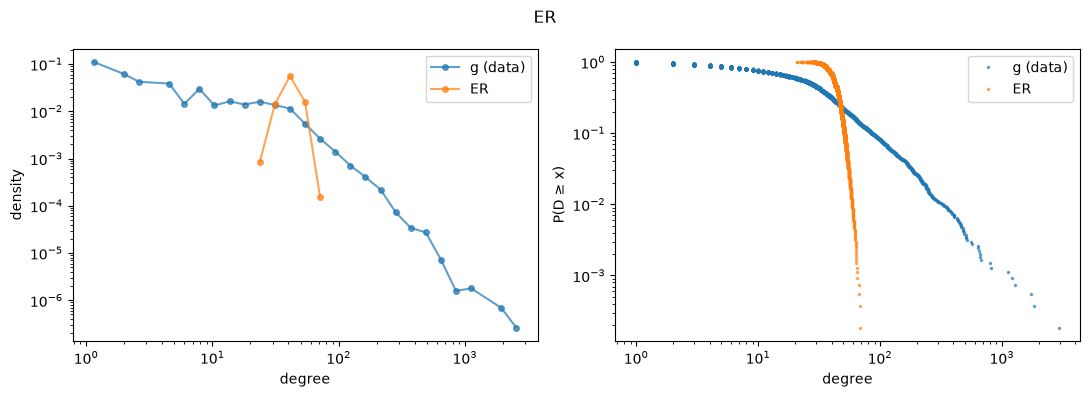

ER: n=5424, m=116365, mean deg=42.9, max deg=68, simple=True, connected=True


In [28]:
random.seed(42)                                           # python-igraph draws from Python's random: reproducible
er = ig.Graph.Erdos_Renyi(n=n, m=m, directed=False, loops=False)    # G(n, m): exactly the same order and size as g
stats['er (ER)'] = basic_stats(er)
display(pd.DataFrame.from_dict(stats, orient='index'))

show(er, "ER")

#### Notes / observations

&nbsp;

&nbsp;

&nbsp;

### Task 1.3

Produce a network of approximately the same order and size of $g$ as follows: at each timestamp, add one actor to the network and connect it to $k$ randomly chosen existing actors (equal probability). Store the network into a variable $er\_g$ ($er$ refers to the usage of equal probabilities, as in the ER model, while $g$ refers to the fact that this is a growing model, where nodes are added one by one). Print basic statistics, as a basic validity check.

#### NOTES

- This process looks similar to the one followed by the Preferential Attachment model, but with no preference for any of the existing actors.
- Write your own function for this.
- The description above has to be adapted at the beginning of the process, when the number of actors is less than $k$. Choose any simple and reasonable way to make it work.

#### Student workspace

edges: 113673 (expected 113673, target 116365); simple: True


,nodes,edges,density,mean degree,max degree,components,simple
g (empirical),5424,116365,0.00791,42.91,2927,1,True
er (ER),5424,116365,0.00791,42.91,68,1,True
er_g (growing ER),5424,113673,0.00773,41.91,153,1,True


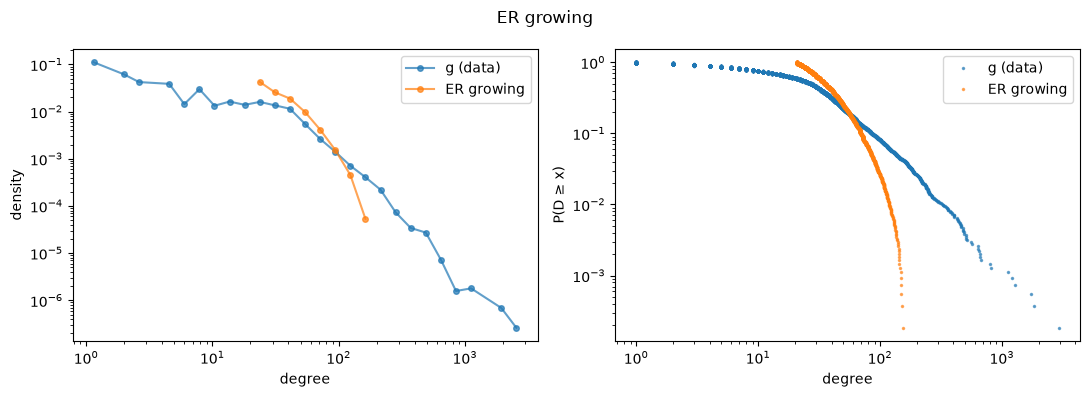

ER growing: n=5424, m=113673, mean deg=41.9, max deg=153, simple=True, connected=True


In [29]:
def generate_er_g(k, n):
    er_g = ig.Graph(n=1)
    for new in range(1,n):
        er_g.add_vertices(1)
        targets = random.sample(range(new), min(k, new))
        er_g.add_edges([(new, t) for t in targets])

    return er_g
        

er_g = generate_er_g(k, n)
# validity check: node number t (t = 1, 2, ...) brings min(t, k) edges
expected = sum(min(t, k) for t in range(1, n))
print(f'edges: {er_g.ecount()} (expected {expected}, target {m}); simple: {er_g.is_simple()}')
stats['er_g (growing ER)'] = basic_stats(er_g)
display(pd.DataFrame.from_dict(stats, orient='index'))

show(er_g, "ER growing")

#### Notes / observations

&nbsp;

&nbsp;

&nbsp;

### Task 1.4

Produce a configuration model network of approximately the same order and size of $g$, and store it into a variable $cm$. Print basic statistics, as a basic validity check.

#### Student workspace

same degree sequence as g: True


,nodes,edges,density,mean degree,max degree,components,simple
g (empirical),5424,116365,0.00791,42.91,2927,1,True
er (ER),5424,116365,0.00791,42.91,68,1,True
er_g (growing ER),5424,113673,0.00773,41.91,153,1,True
cm (configuration),5424,116365,0.00791,42.91,2927,1,True


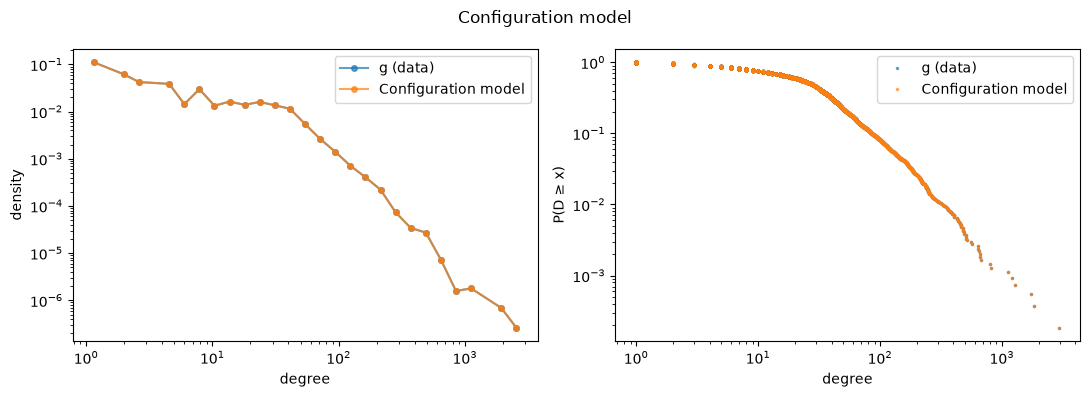

Configuration model: n=5424, m=116365, mean deg=42.9, max deg=2927, simple=True, connected=True


In [30]:
random.seed(42)
# Same degree sequence as g, otherwise random wiring. method='vl' gives a simple (no loops, no multi-edges)
# connected graph; the plain 'configuration' method would create loops and multi-edges, and since g has huge hubs
# many hub-hub edges would be lost when simplifying.
cm = ig.Graph.Degree_Sequence(g.degree(), method='vl')
print('same degree sequence as g:', sorted(cm.degree()) == sorted(g.degree()))
stats['cm (configuration)'] = basic_stats(cm)
display(pd.DataFrame.from_dict(stats, orient='index'))

show(cm, "Configuration model")

#### Notes / observations

&nbsp;

&nbsp;

&nbsp;

### Task 1.5

Produce a PA (Preferential Attachment) network of approximately the same order and size of $g$, and store it into a variable $pa$. Print basic statistics, as a basic validity check.

#### Student workspace

edges: 113673 (er_g has 113673, target 116365); simple: True


,nodes,edges,density,mean degree,max degree,components,simple
g (empirical),5424,116365,0.00791,42.91,2927,1,True
er (ER),5424,116365,0.00791,42.91,68,1,True
er_g (growing ER),5424,113673,0.00773,41.91,153,1,True
cm (configuration),5424,116365,0.00791,42.91,2927,1,True
pa (preferential attachment),5424,113673,0.00773,41.91,495,1,True


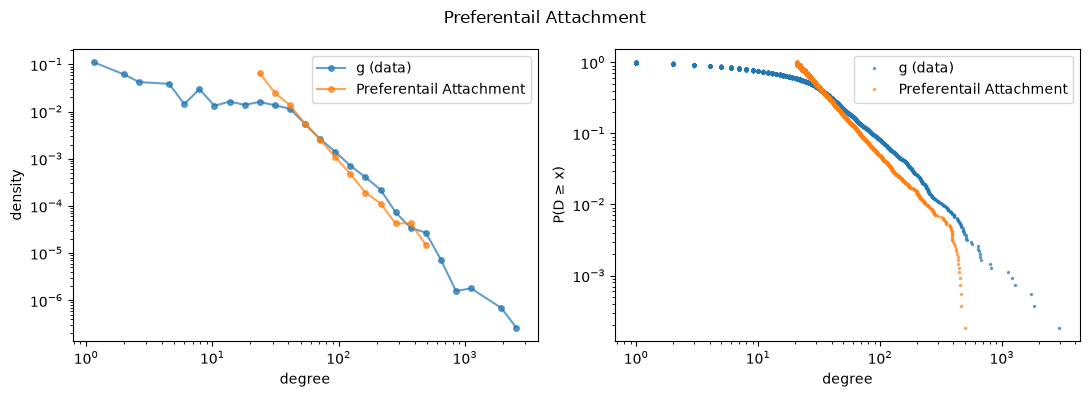

Preferentail Attachment: n=5424, m=113673, mean deg=41.9, max deg=495, simple=True, connected=True


In [31]:
random.seed(42)
# Linear preferential attachment: each new node connects to k existing nodes with probability growing with their degree.
# Same k as er_g, so the only difference between the two is preferential vs. uniform choice.
pa = ig.Graph.Barabasi(n=n, m=k, directed=False, power=1)
print(f'edges: {pa.ecount()} (er_g has {er_g.ecount()}, target {m}); simple: {pa.is_simple()}')
stats['pa (preferential attachment)'] = basic_stats(pa)
display(pd.DataFrame.from_dict(stats, orient='index'))

show(pa, "Preferentail Attachment")

#### Notes / observations

&nbsp;

&nbsp;

&nbsp;

### Task 1.6

Produce a WS (Watts-Strogatz) network of approximately the same order and size of $g$, and store it into a variable $ws$. Print basic statistics, as a basic validity check.

#### Student workspace

edges: 113904 (expected 113904, target 116365); simple: True


,nodes,edges,density,mean degree,max degree,components,simple
g (empirical),5424,116365,0.00791,42.91,2927,1,True
er (ER),5424,116365,0.00791,42.91,68,1,True
er_g (growing ER),5424,113673,0.00773,41.91,153,1,True
cm (configuration),5424,116365,0.00791,42.91,2927,1,True
pa (preferential attachment),5424,113673,0.00773,41.91,495,1,True
ws (Watts-Strogatz),5424,113904,0.00774,42.00,55,1,True


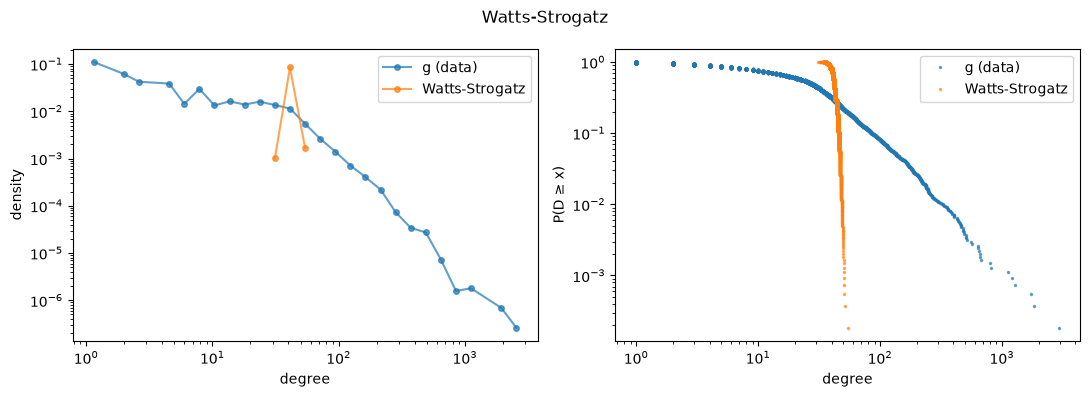

Watts-Strogatz: n=5424, m=113904, mean deg=42.0, max deg=55, simple=True, connected=True


In [ ]:
random.seed(42)
# Watts-Strogatz: ring lattice where every node is connected to its `nei` nearest neighbours on each side
# (n * nei edges, so nei = k gives the size of g), then every edge is rewired with probability p.
# A small p keeps the high clustering of the lattice but creates shortcuts (short paths).
p_rewire = 0.1
ws = ig.Graph.Watts_Strogatz(dim=1, size = n, nei = k, p = p_rewire)
print(f'edges: {ws.ecount()} (expected {n * k}, target {m}); simple: {ws.is_simple()}')
stats['ws (Watts-Strogatz)'] = basic_stats(ws)
display(pd.DataFrame.from_dict(stats, orient='index'))

show(ws, "Watts-Strogatz")

#### Notes / observations

&nbsp;

&nbsp;

&nbsp;

### Task 1.7

Produce a network using a stochastic block model of approximately the same order and size of $g$, and store it into a variable $sbm$. Use the result of a community detection algorithm on $g$ to specify the block number of sizes and the connection probabilities. Print basic statistics, as a basic validity check.

#### Student workspace

Louvain on g: 13 communities, modularity 0.321, sizes [1486, 776, 706, 668, 400, 391, 314, 310, 273, 86, 6, 4, 4]
edges: 116274 (expected 116365, target 116365); simple: True


,nodes,edges,density,mean degree,max degree,components,simple
g (empirical),5424,116365,0.00791,42.91,2927,1,True
er (ER),5424,116365,0.00791,42.91,68,1,True
er_g (growing ER),5424,113673,0.00773,41.91,153,1,True
cm (configuration),5424,116365,0.00791,42.91,2927,1,True
pa (preferential attachment),5424,113673,0.00773,41.91,495,1,True
ws (Watts-Strogatz),5424,113904,0.00774,42.00,55,1,True
sbm (stochastic block model),5424,116274,0.00791,42.87,91,3,True


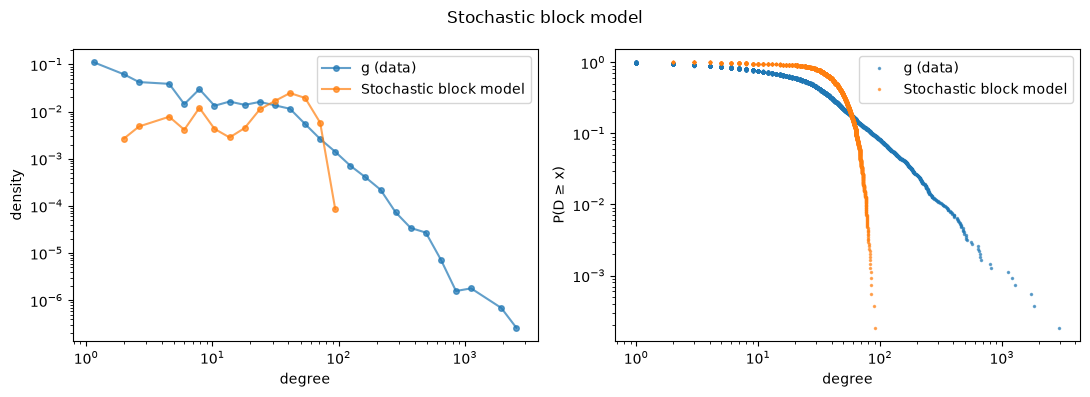

Stochastic block model: n=5424, m=116274, mean deg=42.9, max deg=91, simple=True, connected=False


In [33]:
random.seed(42)
# 1) community detection on g: Louvain (modularity-based, unweighted)
cl = g.community_multilevel(resolution=1.0)
memb = np.array(cl.membership)
B = len(cl)                                               # number of blocks
sizes = np.bincount(memb, minlength=B)                    # block sizes
print(f'Louvain on g: {B} communities, modularity {g.modularity(memb.tolist()):.3f}, sizes {sorted(sizes.tolist(), reverse=True)}')

# 2) number of edges between (and inside) the blocks
el = np.array(g.get_edgelist())
bi, bj = memb[el[:, 0]], memb[el[:, 1]]
E = np.zeros((B, B))
np.add.at(E, (np.minimum(bi, bj), np.maximum(bi, bj)), 1)
E = E + E.T - np.diag(np.diag(E))                         # symmetric; the diagonal = edges inside a block

# 3) connection probability = observed edges / possible edges
possible = np.outer(sizes, sizes).astype(float)           # pairs between block i and block j
np.fill_diagonal(possible, sizes * (sizes - 1) / 2)       # pairs inside a block
pref = np.divide(E, possible, out=np.zeros_like(E), where=possible > 0)

# 4) generate the network (vertices are numbered block by block)
sbm = ig.Graph.SBM(pref.tolist(), sizes.tolist())
sbm.vs['block'] = np.repeat(np.arange(B), sizes).tolist() # planted blocks, useful for Task 2.3

expected_edges = (np.triu(pref) * np.triu(possible)).sum()
print(f'edges: {sbm.ecount()} (expected {expected_edges:.0f}, target {m}); simple: {sbm.is_simple()}')
stats['sbm (stochastic block model)'] = basic_stats(sbm)
display(pd.DataFrame.from_dict(stats, orient='index'))

show(sbm, "Stochastic block model")

#### Notes / observations

&nbsp;

&nbsp;

&nbsp;

## PART 2: Measures

### Task 2.1

Compute centralisation for all the networks. Feel free to choose the centralisation function(s) to use in this task.

#### TIPS
- For the measures you choose, also produce a plot of their distribution (e.g. degree distribution for degree centralisation). This is useful for face validity, but also to allow you to better understand how the micro-level measure(s) you use to compute centralisation vary in the different networks.

#### Student workspace

#### Notes / observations

&nbsp;

&nbsp;

&nbsp;

### Task 2.2

Compute cohesion for all the networks. Feel free to choose the cohesion function(s) to use in this task, but use at least average path length and one measure of network-level clustering.

#### Student workspace

#### Notes / observations

&nbsp;

&nbsp;

&nbsp;

### Task 2.3

Compute segregation using the communities you discovered as groups and categorical assortativity as a function.

#### NOTES
- You already have communities for $g$ and $sbm$. You have to discover communities on the other networks too. Reflect on which method is the most appropriate to be able to compare the results across networks.
- IF you have classified the actors in your network into other types of groups, feel free to also quantify segregation between those groups.

#### Student workspace

#### Notes / observations

&nbsp;

&nbsp;

&nbsp;

### Task 2.4

Compute numerical assortativy using degree as a variable. What does this measure represent?

#### Student workspace

#### Notes / observations

&nbsp;

&nbsp;

&nbsp;

## PART 3: Summary

### Task 3.1

Produce a summary table with all your results from Part 2. You will use this table for your discussion with the teacher.

#### TIPS
- You should have already reflected about all the numbers that you are now organising into a single table. However, looking at all of them together may be used as one additional validation step: look if any values seem suspicious, and if they do, think of whether the corresponding network model is compatible with them, or double-check your code.

#### Student workspace

#### Notes / observations

&nbsp;

&nbsp;

&nbsp;